<a href="https://colab.research.google.com/github/mehercodesai/Cat_Dog_Classification/blob/main/Cat%26DogCNN_with_Transfer_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Load packages**

In [ ]:
import os, cv2, random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from tqdm import tqdm
from random import shuffle
from IPython.display import SVG
from keras.utils import model_to_dot, plot_model
from keras.applications import ResNet50
from keras.models import Sequential
from keras.layers import Dense, Flatten, GlobalAveragePooling2D
%matplotlib inline

## **Parameters**

In [ ]:
!pip install -q kaggle
# Upload your kaggle.json API token when prompted,
from google.colab import files
files.upload()


# Download and unzip the dataset
!kaggle competitions download -c dogs-vs-cats-redux-kernels-edition
!unzip -q dogs-vs-cats-redux-kernels-edition.zip -d ./kaggle/input/dogs-vs-cats-redux-kernels-edition/

Saving archive.zip to archive.zip
You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication
unzip:  cannot find or open dogs-vs-cats-redux-kernels-edition.zip, dogs-vs-cats-redux-kernels-edition.zip.zip or dogs-vs-cats-redux-kernels-edition.zip.ZIP.


In [ ]:
TEST_SIZE = 0.5
RANDOM_STATE = 2018
BATCH_SIZE = 64
NO_EPOCHS = 20
NUM_CLASSES = 2
SAMPLE_SIZE = 20000
PATH = './'
TRAIN_FOLDER = './train/'
TEST_FOLDER = './test/'
IMG_SIZE = 224
RESNET_WEIGHTS_PATH = "imagenet"

In [ ]:
train_image_path = os.path.join(PATH, "train.zip")
test_image_path = os.path.join(PATH, "test.zip")

In [ ]:
import zipfile

# Extract the uploaded dataset
with zipfile.ZipFile('archive.zip', 'r') as z:
    z.extractall('.')

In [ ]:
import os
print("Root files:", os.listdir('.'))

Root files: ['.config', 'archive.zip', 'test', 'train', 'sample_data']


In [ ]:
def label_pet_image_one_hot_encoder(img):
    pet = img.split('.')[-3]
    if pet == 'cat': return [1,0]
    elif pet == 'dog': return [0,1]

In [ ]:
from tensorflow.keras.applications.resnet50 import preprocess_input

def process_data(data_image_list, DATA_FOLDER, isTrain=True):
    data_df = []

    for img_path in tqdm(data_image_list):

        path = os.path.join(DATA_FOLDER, img_path)

        # Get label from folder name
        folder_name = os.path.basename(os.path.dirname(img_path)).lower()

        if 'cat' in folder_name:
            label = [1, 0]
        elif 'dog' in folder_name:
            label = [0, 1]
        else:
            raise ValueError(f"Unknown label: {img_path}")

        # Read image
        img = cv2.imread(path)

        # OpenCV BGR → RGB
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Resize
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

        # ResNet50 preprocessing
        img = preprocess_input(img.astype(np.float32))

        data_df.append([
            np.array(img),
            np.array(label)
        ])

    shuffle(data_df)

    return data_df

## **Data exploration**

**Class distribution**

In [ ]:
import os

# Set your training directory path
TRAIN_DIR = 'train'  # or your specific path, e.g., './data/train'

# Define train_image_list
train_image_list = os.listdir(TRAIN_DIR)

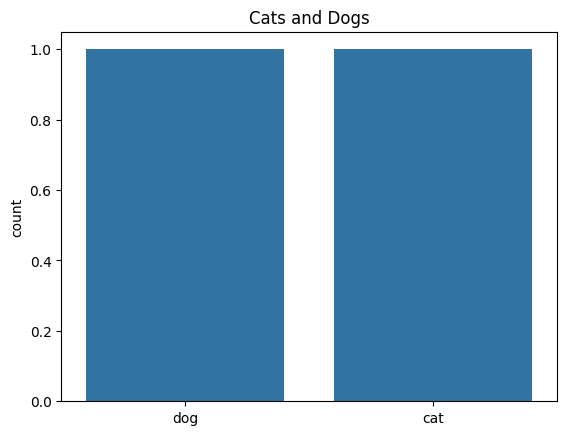

In [ ]:
def plot_image_list_count(data_image_list):
    labels = []
    for img in data_image_list:
        if 'cat' in img.lower():
            labels.append('cat')
        elif 'dog' in img.lower():
            labels.append('dog')
        else:
            continue

    sns.countplot(x=labels)
    plt.title('Cats and Dogs')
    plt.show()

plot_image_list_count(train_image_list)

In [ ]:
def label_pet_image_one_hot_encoder(img):
    # Extract filename or directory name depending on path structure
    if 'cat' in img.lower():
        return [1, 0]
    elif 'dog' in img.lower():
        return [0, 1]
    else:
        raise ValueError(f"Unknown label in path: {img}")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def show_images(data_list, isTest=False):
    fig, ax = plt.subplots(5, 5, figsize=(12, 12))
    for i, data in enumerate(data_list[:25]):
        img_data = data[0]
        img_num = data[1]

        # Check label encoding
        if isTest:
            str_label = f"Image #{img_num}"
        else:
            label = np.argmax(img_num)
            str_label = 'Dog' if label == 1 else 'Cat'

        ax[i // 5, i % 5].imshow(cv2.cvtColor(img_data, cv2.COLOR_BGR2RGB))
        ax[i // 5, i % 5].axis('off')
        ax[i // 5, i % 5].set_title(str_label)

    plt.tight_layout()
    plt.show()

100%|██████████| 557/557 [00:03<00:00, 184.16it/s]


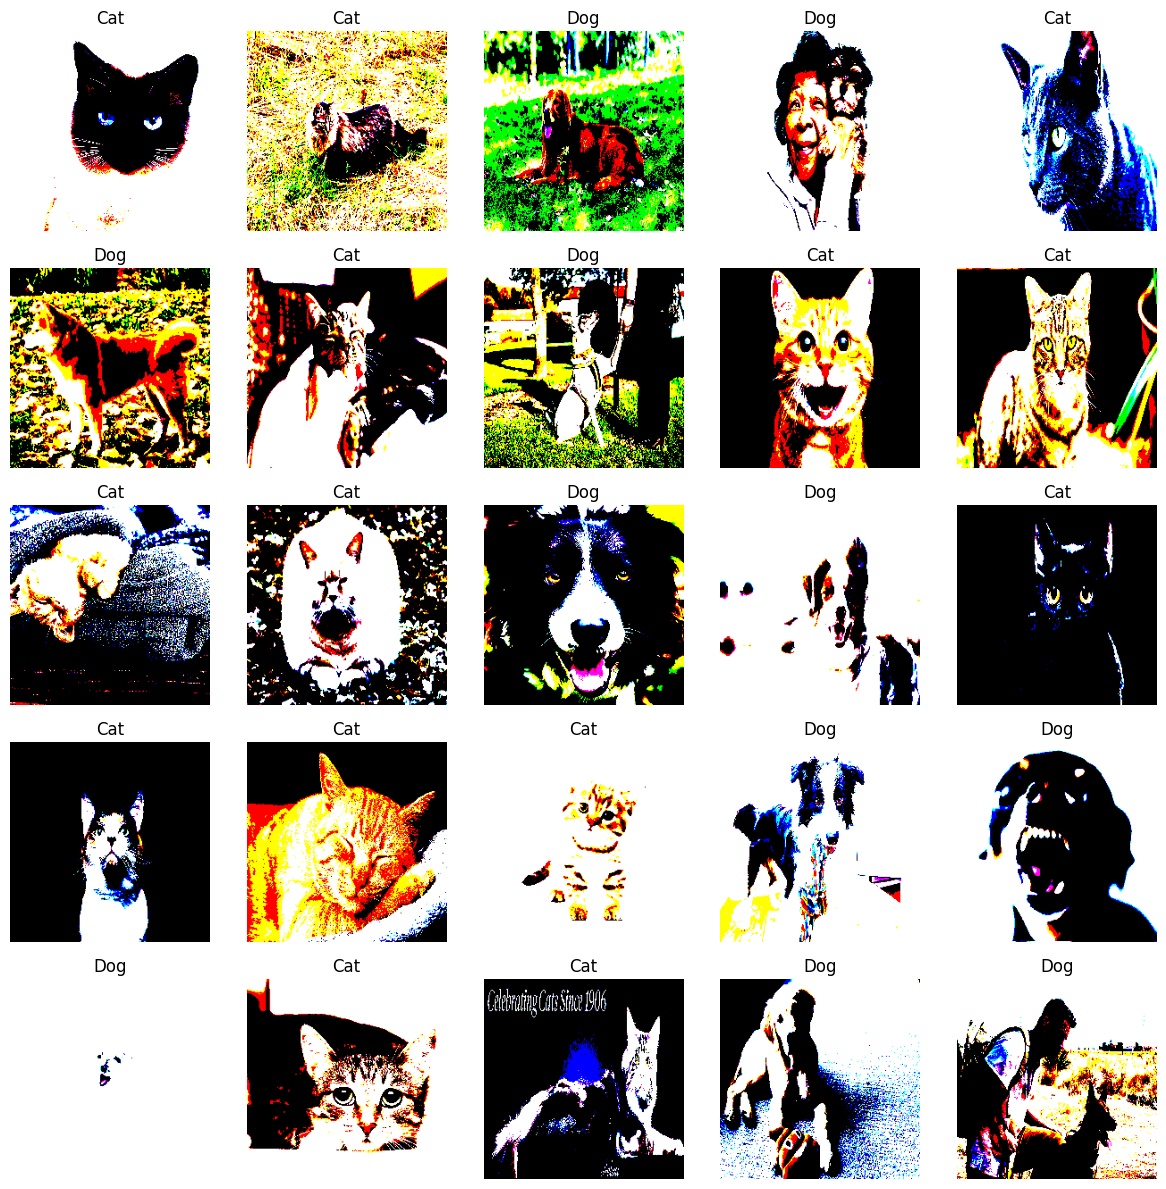

In [ ]:
import os
import cv2
import numpy as np
from tqdm import tqdm
from random import shuffle

# 1. Walk through 'train' directory and subdirectories to find all image files
DATA_FOLDER = 'train'
data_image_list = []

for root, dirs, files in os.walk(DATA_FOLDER):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            # Store relative path from DATA_FOLDER (e.g., 'dogs/dog_1.jpg')
            rel_path = os.path.relpath(os.path.join(root, file), DATA_FOLDER)
            data_image_list.append(rel_path)

# 2. Process the images
train = process_data(data_image_list, DATA_FOLDER, isTrain=True)

# 3. Display the images
show_images(train, isTest=False)

In [ ]:

def show_images(data_list, isTest=False):
    fig, ax = plt.subplots(5, 5, figsize=(12, 12))
    for i, data in enumerate(data_list[:25]):
        img_data = data[0]
        img_num = data[1]

        if isTest:
            str_label = f"Image #{img_num}"
        else:
            label = np.argmax(img_num)
            str_label = 'Dog' if label == 1 else 'Cat'

        # Convert BGR to RGB for correct color display with Matplotlib
        ax[i // 5, i % 5].imshow(cv2.cvtColor(img_data, cv2.COLOR_BGR2RGB))
        ax[i // 5, i % 5].axis('off')
        ax[i // 5, i % 5].set_title(str_label)

    plt.tight_layout()
    plt.show()

100%|██████████| 140/140 [00:00<00:00, 199.49it/s]


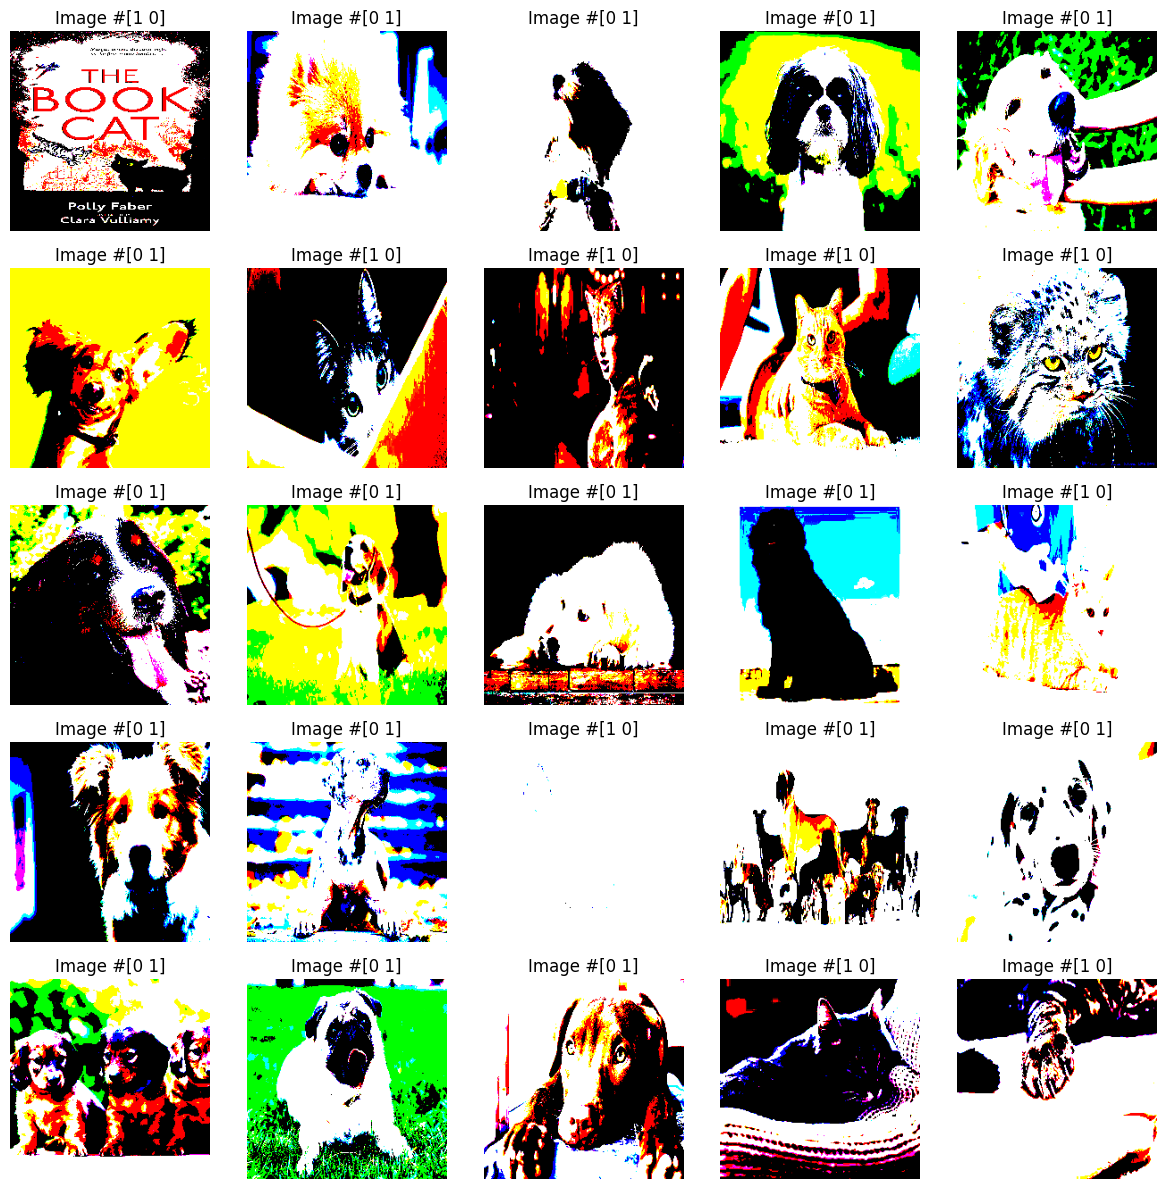

In [ ]:
# 1. Walk through 'test' directory
TEST_FOLDER = 'test'
test_image_list = []

for root, dirs, files in os.walk(TEST_FOLDER):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            rel_path = os.path.relpath(os.path.join(root, file), TEST_FOLDER)
            test_image_list.append(rel_path)

# 2. Process test images
test = process_data(test_image_list, TEST_FOLDER, isTrain=False)

# 3. Display test images
show_images(test, isTest=True)

## **Model**

In [ ]:
X = np.array([i[0] for i in train]).reshape(-1,IMG_SIZE,IMG_SIZE,3)
y = np.array([i[1] for i in train])

In [ ]:
model = Sequential()
model.add(ResNet50(include_top=False, pooling='max', weights=RESNET_WEIGHTS_PATH))
model.add(Dense(NUM_CLASSES, activation='softmax'))
# ResNet-50 model is already trained, should not be trained
model.layers[0].trainable = False

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
model.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 2048)           │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         4,098 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,591,810 (90.00 MB)

 Trainable params: 4,098 (16.01 KB)

 Non-trainable params: 23,587,712 (89.98 MB)



In [ ]:
from tensorflow.keras.utils import plot_model

# Generate and display the model architecture graph
plot_model(
    model,
    to_file='model_architecture.png',
    show_shapes=True,
    show_dtype=False,
    show_layer_names=True,
    expand_nested=True,
    dpi=96
)

# **Split the train data in train and validation**

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

# **Train the model**

In [ ]:
history = model.fit(X_train, y_train,
                  batch_size=BATCH_SIZE,
                  epochs=50,
                  verbose=1,
                  validation_data=(X_val, y_val))

Epoch 1/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 28s 3s/step - accuracy: 0.5468 - loss: 82.7692 - val_accuracy: 0.9391 - val_loss: 1.8545
Epoch 2/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 299ms/step - accuracy: 0.9748 - loss: 0.5818 - val_accuracy: 0.9319 - val_loss: 2.2034
Epoch 3/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 298ms/step - accuracy: 0.9784 - loss: 0.4571 - val_accuracy: 0.9319 - val_loss: 1.6605
Epoch 4/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 299ms/step - accuracy: 0.9928 - loss: 0.1786 - val_accuracy: 0.9821 - val_loss: 0.4594
Epoch 5/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 303ms/step - accuracy: 0.9964 - loss: 0.0160 - val_accuracy: 0.9821 - val_loss: 0.3685
Epoch 6/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 310ms/step - accuracy: 1.0000 - loss: 4.4566e-05 - val_accuracy: 0.9821 - val_loss: 0.3691
Epoch 7/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 303ms/step - accuracy: 1.0000 - loss: 3.2874e-05 - val_accuracy: 0.9821 - val_loss: 0.3695
Epoch 8/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 301ms/step - accuracy: 1.0000 - loss: 2.6257e-05 - val_accuracy: 0.9857 

In [ ]:
# Install Graphviz system package and pydot python package
!apt-get install -y graphviz
!pip install pydot

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
graphviz is already the newest version (2.42.2-9ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 52 not upgraded.


Final Training Accuracy:   1.0000 (100.00%)
Final Validation Accuracy: 0.9857 (98.57%)
Best Validation Accuracy:  0.9857 (98.57%) [Epoch 8]
---------------------------------------------
Final Training Loss:       0.0000
Final Validation Loss:     0.3763
Lowest Validation Loss:    0.3685 [Epoch 5]


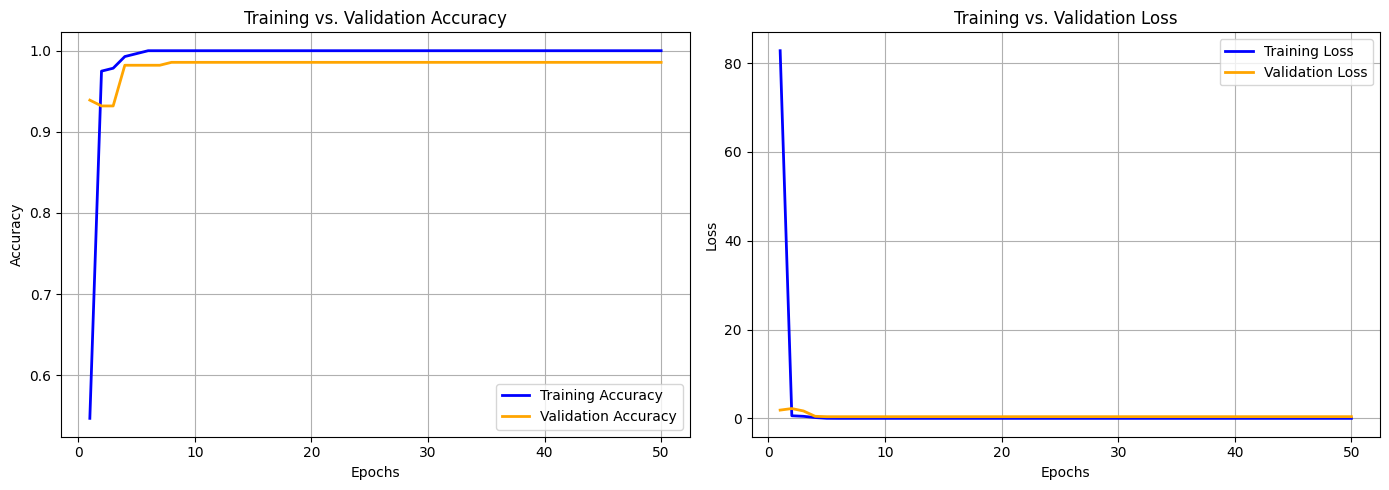

In [ ]:
import matplotlib.pyplot as plt

# 1. Retrieve history metrics safely
acc = history.history.get('accuracy') or history.history.get('acc')
val_acc = history.history.get('val_accuracy') or history.history.get('val_acc')
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(loss) + 1)

# 2. Print Numeric Summary
print("=" * 45)
print(f"Final Training Accuracy:   {acc[-1]:.4f} ({acc[-1]*100:.2f}%)")
print(f"Final Validation Accuracy: {val_acc[-1]:.4f} ({val_acc[-1]*100:.2f}%)")
print(f"Best Validation Accuracy:  {max(val_acc):.4f} ({max(val_acc)*100:.2f}%) [Epoch {val_acc.index(max(val_acc)) + 1}]")
print("-" * 45)
print(f"Final Training Loss:       {loss[-1]:.4f}")
print(f"Final Validation Loss:     {val_loss[-1]:.4f}")
print(f"Lowest Validation Loss:    {min(val_loss):.4f} [Epoch {val_loss.index(min(val_loss)) + 1}]")
print("=" * 45)

# 3. Create Side-by-Side Graphs
plt.figure(figsize=(14, 5))

# Subplot 1: Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', color='blue', linewidth=2)
plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='orange', linewidth=2)
plt.title('Training vs. Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

# Subplot 2: Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', color='blue', linewidth=2)
plt.plot(epochs_range, val_loss, label='Validation Loss', color='orange', linewidth=2)
plt.title('Training vs. Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# Create a clean table of all epoch metrics
history_df = pd.DataFrame(history.history)
history_df.index = [f"Epoch {i+1}" for i in range(len(history_df))]
print("\nEpoch-by-Epoch Performance:")
display(history_df)


Epoch-by-Epoch Performance:


,accuracy,loss,val_accuracy,val_loss
Epoch 1,0.546763,82.769249,0.939068,1.854514
Epoch 2,0.974820,0.581821,0.931900,2.203434
Epoch 3,0.978417,0.457096,0.931900,1.660545
Epoch 4,0.992806,0.178560,0.982079,0.459447
Epoch 5,0.996403,0.016028,0.982079,0.368479
Epoch 6,1.000000,0.000045,0.982079,0.369067
Epoch 7,1.000000,0.000033,0.982079,0.369546
Epoch 8,1.000000,0.000026,0.985663,0.369957
Epoch 9,1.000000,0.000022,0.985663,0.370318
Epoch 10,1.000000,0.000019,0.985663,0.370642


In [ ]:
score = model.evaluate(X_val, y_val, verbose=0)
print('Validation loss:', score[0])
print('Validation accuracy:', score[1])

Validation loss: 0.37627723813056946
Validation accuracy: 0.9856630563735962


9/9 ━━━━━━━━━━━━━━━━━━━━ 8s 579ms/step
PER-CLASS VALIDATION ACCURACY
Accuracy for Cat  : 0.9799 (97.99%)
Accuracy for Dog  : 0.9923 (99.23%)

Classification Report:
              precision    recall  f1-score   support

         Cat       0.99      0.98      0.99       149
         Dog       0.98      0.99      0.98       130

    accuracy                           0.99       279
   macro avg       0.99      0.99      0.99       279
weighted avg       0.99      0.99      0.99       279



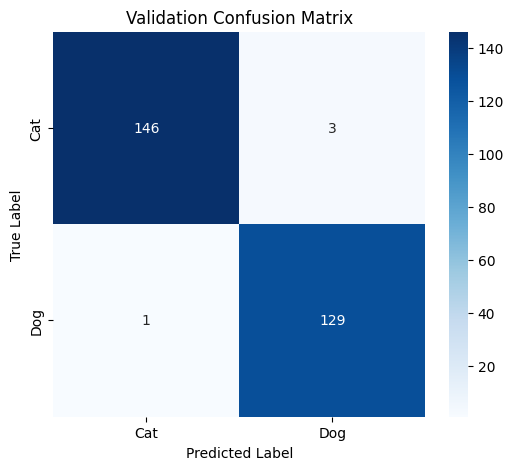

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Obtain predictions on validation data
# If using validation split from array X_val, Y_val:
y_pred_probs = model.predict(X_val)
y_pred_classes = np.argmax(y_pred_probs, axis=1)
y_true_classes = np.argmax(y_val, axis=1)

# Class names corresponding to target labels
class_names = ['Cat', 'Dog']

# 2. Compute confusion matrix and per-class accuracies
cm = confusion_matrix(y_true_classes, y_pred_classes)
class_accuracies = cm.diagonal() / cm.sum(axis=1)

print("=" * 45)
print("PER-CLASS VALIDATION ACCURACY")
print("=" * 45)
for i, name in enumerate(class_names):
    print(f"Accuracy for {name:5s}: {class_accuracies[i]:.4f} ({class_accuracies[i]*100:.2f}%)")
print("=" * 45)

# 3. Print detailed Classification Report (Precision, Recall, F1-Score)
print("\nClassification Report:")
print(classification_report(y_true_classes, y_pred_classes, target_names=class_names))

# 4. Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Validation Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_176
Received: inputs=('Tensor(shape=(1, 224, 224, 3))',)
  warnings.warn(msg)


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


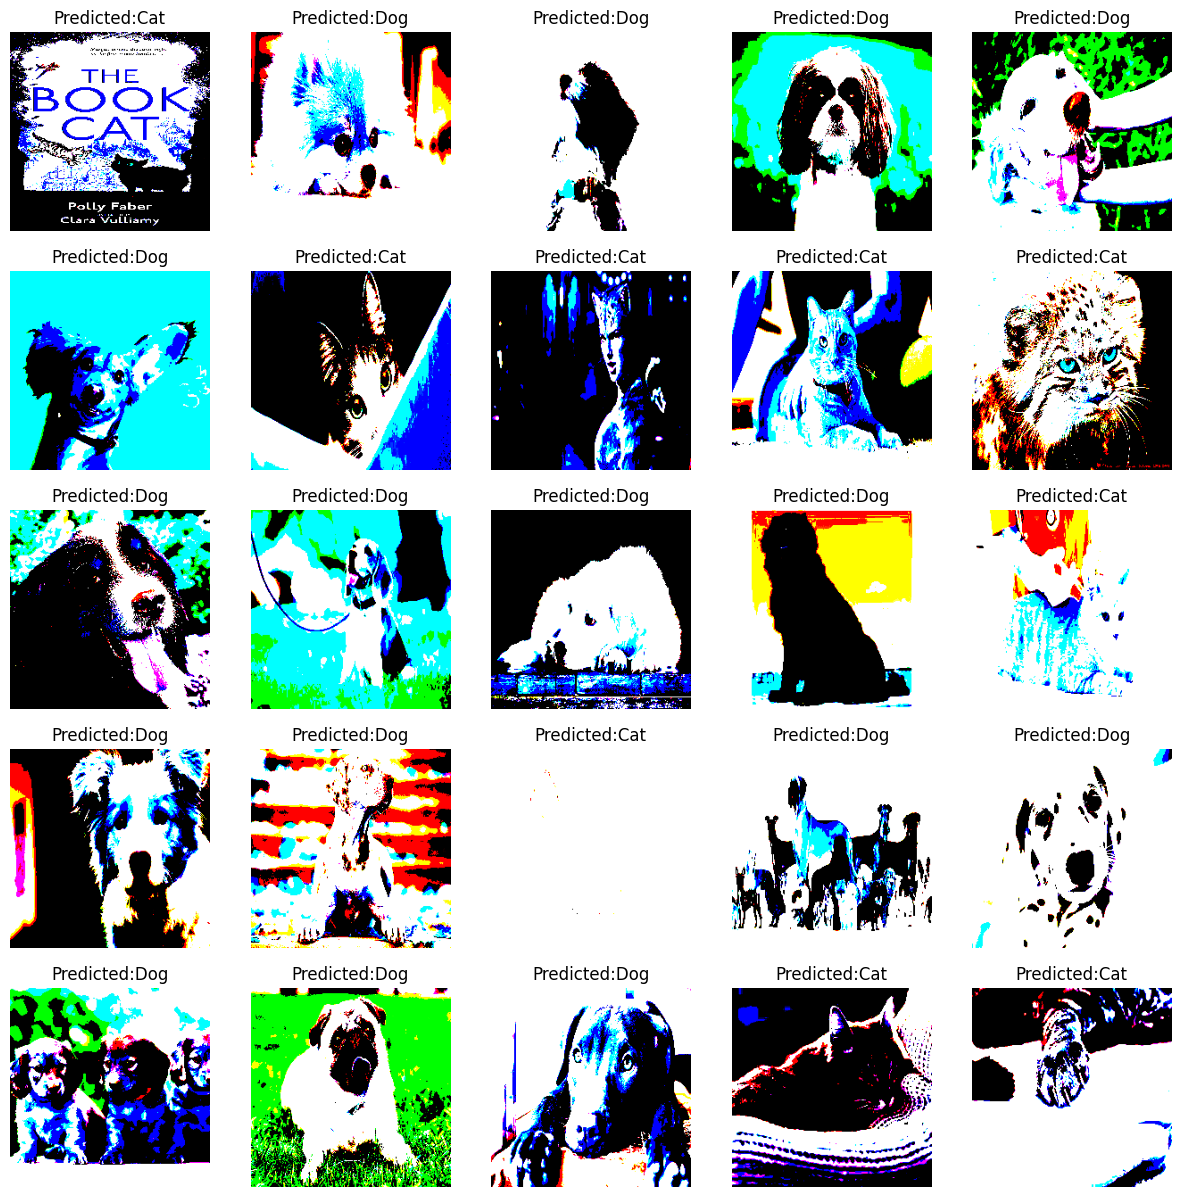

In [ ]:
f, ax = plt.subplots(5,5, figsize=(15,15))
for i,data in enumerate(test[:25]):
    img_num = data[1]
    img_data = data[0]
    orig = img_data
    data = img_data.reshape(-1,IMG_SIZE,IMG_SIZE,3)
    model_out = model.predict([data])[0]

    if np.argmax(model_out) == 1:
        str_predicted='Dog'
    else:
        str_predicted='Cat'
    ax[i//5, i%5].imshow(orig)
    ax[i//5, i%5].axis('off')
    ax[i//5, i%5].set_title("Predicted:{}".format(str_predicted))
plt.show()

5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 912ms/step


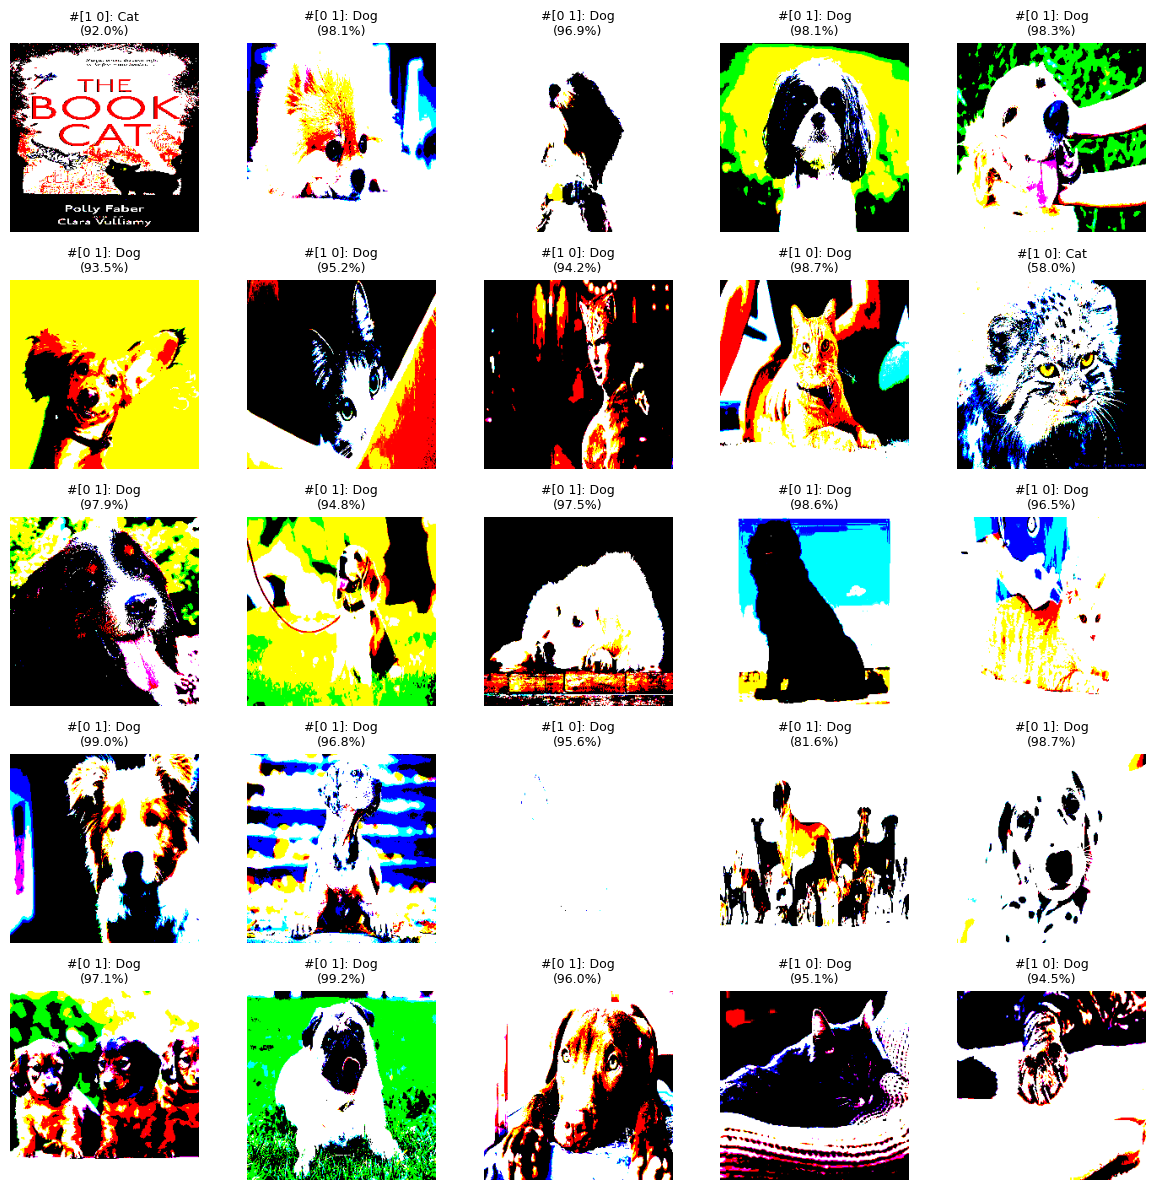

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

# 1. Format test array explicitly
X_test = np.array([cv2.resize(data[0], (IMG_SIZE, IMG_SIZE)) for data in test], dtype=np.float32)
X_test = X_test / 255.0  # Match training normalization

# 2. Predict on test images
predictions = model.predict(X_test)

# 3. Display first 25 predictions
fig, ax = plt.subplots(5, 5, figsize=(12, 12))

for i, data in enumerate(test[:25]):
    img_data = data[0]
    img_id = data[1]

    pred_prob = predictions[i]
    pred_label = np.argmax(pred_prob)
    confidence = pred_prob[pred_label] * 100

    str_label = "Dog" if pred_label == 1 else "Cat"

    # Display BGR -> RGB
    ax[i // 5, i % 5].imshow(cv2.cvtColor(img_data, cv2.COLOR_BGR2RGB))
    ax[i // 5, i % 5].axis('off')
    ax[i // 5, i % 5].set_title(f"#{img_id}: {str_label}\n({confidence:.1f}%)", fontsize=9)

plt.tight_layout()
plt.show()

## **Test on Unseen images**

Please upload an image (cat or dog):


Saving images (3).jpg to images (3).jpg


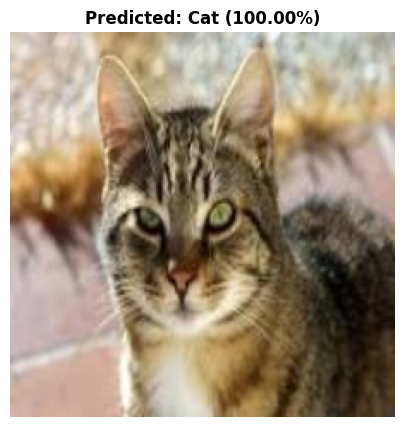

In [ ]:
import io
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from tensorflow.keras.applications.resnet50 import preprocess_input

# 1. Prompt user to upload an image from local machine
print("Please upload an image (cat or dog):")
uploaded = files.upload()

for filename in uploaded.keys():
    # Read image from byte stream
    file_bytes = np.frombuffer(uploaded[filename], np.uint8)
    img_bgr = cv2.imdecode(file_bytes, cv2.IMREAD_COLOR)

    if img_bgr is not None:
        # Convert BGR to RGB for correct display
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # Resize image to match model input (224x224)
        img_resized = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))

        # Preprocess for ResNet50 input shape (1, 224, 224, 3)
        img_prep = preprocess_input(img_resized.astype(np.float32))
        img_batch = np.expand_dims(img_prep, axis=0)

        # Predict class
        prediction = model.predict(img_batch, verbose=0)[0]
        class_names = ['Cat', 'Dog']
        pred_label_idx = np.argmax(prediction)
        pred_class = class_names[pred_label_idx]
        confidence = prediction[pred_label_idx] * 100

        # Display uploaded image with prediction
        plt.figure(figsize=(5, 5))
        plt.imshow(img_resized)
        plt.axis('off')
        plt.title(f"Predicted: {pred_class} ({confidence:.2f}%)", fontsize=12, fontweight='bold')
        plt.show()
    else:
        print(f"Failed to load image: {filename}")